In [26]:
%pip install statsmodels

  Obtaining dependency information for statsmodels from https://files.pythonhosted.org/packages/03/e3/d863228849da191d37c54bdd72634fbbcfadd12e910e29e4bdca1b952bb6/statsmodels-0.15.0-cp312-cp312-win_amd64.whl.metadata
  Obtaining dependency information for patsy>=0.5.6 from https://files.pythonhosted.org/packages/20/70/cd3cf5cff538323076a879edef02cce6f13f7d75e03d12f211b0a0dbd178/patsy-1.0.3-py2.py3-none-any.whl.metadata
  Obtaining dependency information for formulaic>=1.1.0 from https://files.pythonhosted.org/packages/fc/75/0576b03f7889ad25b5385b4f6c69e0543713425a6f193b056c9b0a2e65ce/formulaic-1.2.2-py3-none-any.whl.metadata
  Obtaining dependency information for interface-meta>=1.2.0 from https://files.pythonhosted.org/packages/a1/d3/20a61a248feb1249cd81f83ce731f0bdf5170ed96a08a298f7081cda9e90/interface_meta-2.0.1-py3-none-any.whl.metadata
  Obtaining dependency information for narwhals>=1.17 from https://files.pythonhosted.org/packages/cf/82/8ef9c7e0f50493307a49c09cfa7f00c5a778b6d192


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [6]:
# Tampilan grafik
%matplotlib inline
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [18]:
# Load data bersih
df = pd.read_csv('../data/processed/airbnb_clean.csv')

print(f"Jumlah data: {len(df)} baris")
df[['harga', 'log_harga', 'rating', 'rating_adj', 'jumlah_review', 'kecamatan', 'kabupaten_kota', 'region']].head(10)

Jumlah data: 573 baris


,harga,log_harga,rating,rating_adj,jumlah_review,kecamatan,kabupaten_kota,region
0,9848899,16.102870,5.00,4.968317,33,Cibeunying Kaler,Kota Bandung,Bandung Raya
1,3446781,15.052952,4.98,4.971695,132,Cidadap,Kota Bandung,Bandung Raya
2,12500000,16.341239,4.95,4.943931,112,Sukajadi,Kota Bandung,Bandung Raya
3,2054119,14.535358,4.87,4.878099,38,Cidadap,Kota Bandung,Bandung Raya
4,9883877,16.106416,4.98,4.961503,51,Cidadap,Kota Bandung,Bandung Raya
5,8312500,15.933271,4.80,4.859169,10,Cidadap,Kota Bandung,Bandung Raya
6,9498548,16.066650,4.96,4.958045,456,Parongpong,Kabupaten Bandung Barat,Bandung Raya
7,1990000,14.503646,NaN,NaN,0,Cicendo,Kota Bandung,Bandung Raya
8,2163548,14.587260,4.99,4.981590,148,Cidadap,Kota Bandung,Bandung Raya
9,6961180,15.755860,4.98,4.971639,131,Bandung Wetan,Kota Bandung,Bandung Raya


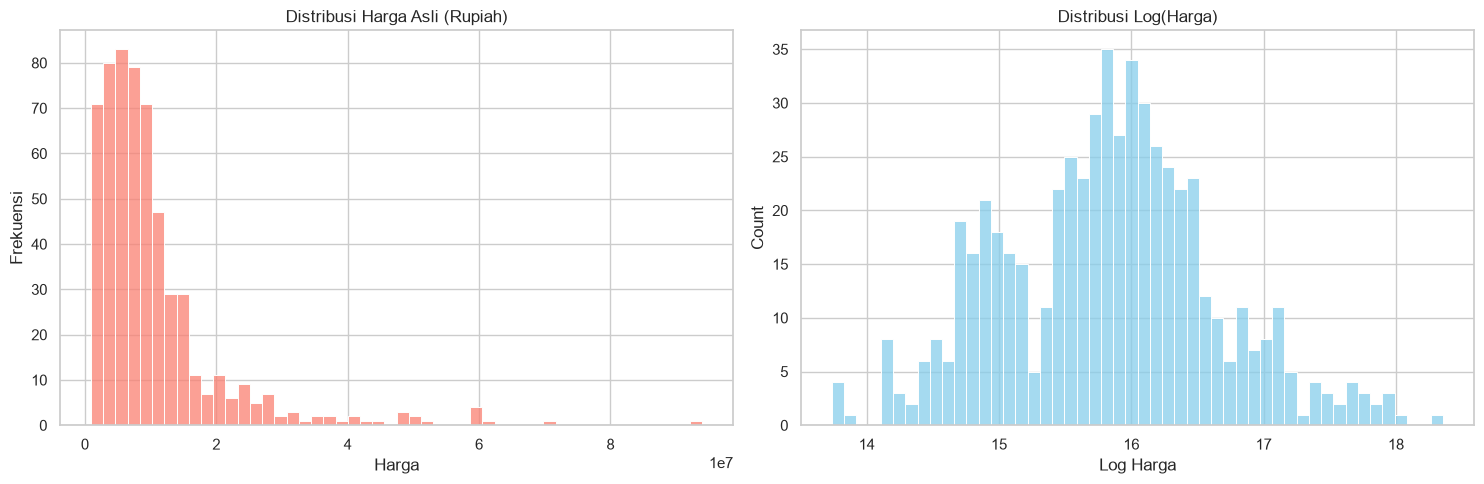

In [ ]:
# Membuat grafik perbandingan harga sebelum dan sesudah transformasi logaritma
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Grafik 1: Harga Asli 
sns.histplot(df['harga'], bins=50, ax=axes[0], color='salmon')
axes[0].set_title('Distribusi Harga Asli (Rupiah)')
axes[0].set_xlabel('Harga')
axes[0].set_ylabel('Frekuensi')

# Grafik 2: Harga Logaritma 
sns.histplot(df['log_harga'], bins=50, ax=axes[1], color='skyblue')
axes[1].set_title('Distribusi Log(Harga)')
axes[1].set_xlabel('Log Harga')

plt.tight_layout()
plt.show()

C:\Users\Acer\AppData\Local\Temp\ipykernel_3016\2085820092.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = df_eda, x='region', y='log_harga', ax=axes[0], palette='Set2')
C:\Users\Acer\AppData\Local\Temp\ipykernel_3016\2085820092.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = df_top10_kec, y='kecamatan', x='log_harga', order=top_10_kec, ax=axes[1], palette='viridis')


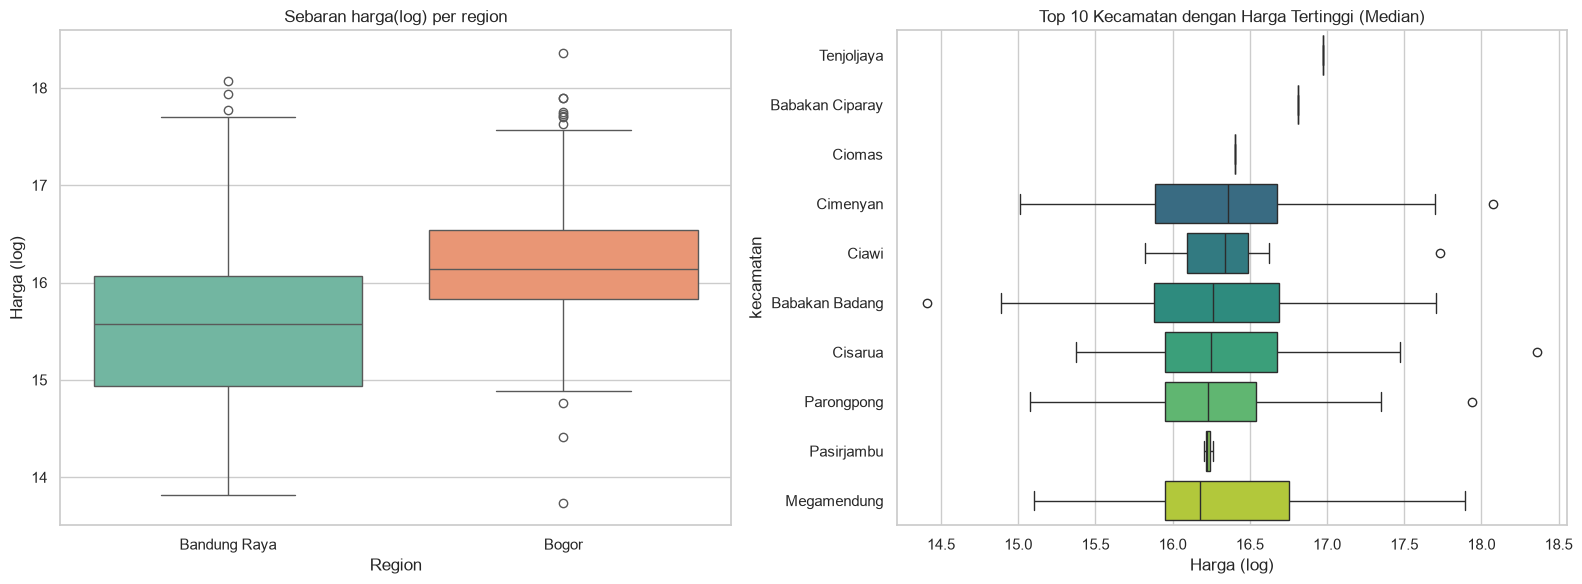

Median Harga per Region (Juta Rupiah):
region
Bandung Raya     5.8
Bogor           10.2
Name: harga, dtype: float64

Top 5 Kecamatan Termahal (Median Harga Juta Rupiah):
kecamatan
Tenjoljaya         23.5
Babakan Ciparay    20.0
Ciomas             13.3
Cimenyan           12.8
Ciawi              12.5
Name: harga, dtype: float64


In [28]:
# Harga berdasarkan wilayah

# Dataframe khusus untuk EDA (Hanya Bandung Raya dan Bogor)
df_eda = df[df['region'].isin(['Bandung Raya', 'Bogor'])].copy()

fig, axes = plt.subplots(1, 2, figsize=(16,6))

# Grafik 1: Perbandingan harga per region
sns.boxplot(data = df_eda, x='region', y='log_harga', ax=axes[0], palette='Set2')
axes[0].set_title("Sebaran harga(log) per region")
axes[0].set_xlabel('Region')
axes[0].set_ylabel('Harga (log)')

# Grafik 2: Top 10 kecamatan dengan harga tertinggi (Berdasarkan median)
top_10_kec = df_eda.groupby('kecamatan')['harga'].median().sort_values(ascending=False).head(10).index
df_top10_kec = df_eda[df_eda['kecamatan'].isin(top_10_kec)]

sns.boxplot(data = df_top10_kec, y='kecamatan', x='log_harga', order=top_10_kec, ax=axes[1], palette='viridis')
axes[1].set_title("Top 10 Kecamatan dengan Harga Tertinggi (Median)")
axes[1].set_ylabel('kecamatan')
axes[1].set_xlabel('Harga (log)')

plt.tight_layout()
plt.show()

print("Median Harga per Region (Juta Rupiah):")
print((df_eda.groupby('region')['harga'].median() / 1_000_000).round(1))

print("\nTop 5 Kecamatan Termahal (Median Harga Juta Rupiah):")
print((df_eda.groupby('kecamatan')['harga'].median() / 1_000_000).sort_values(ascending=False).head(5).round(1))

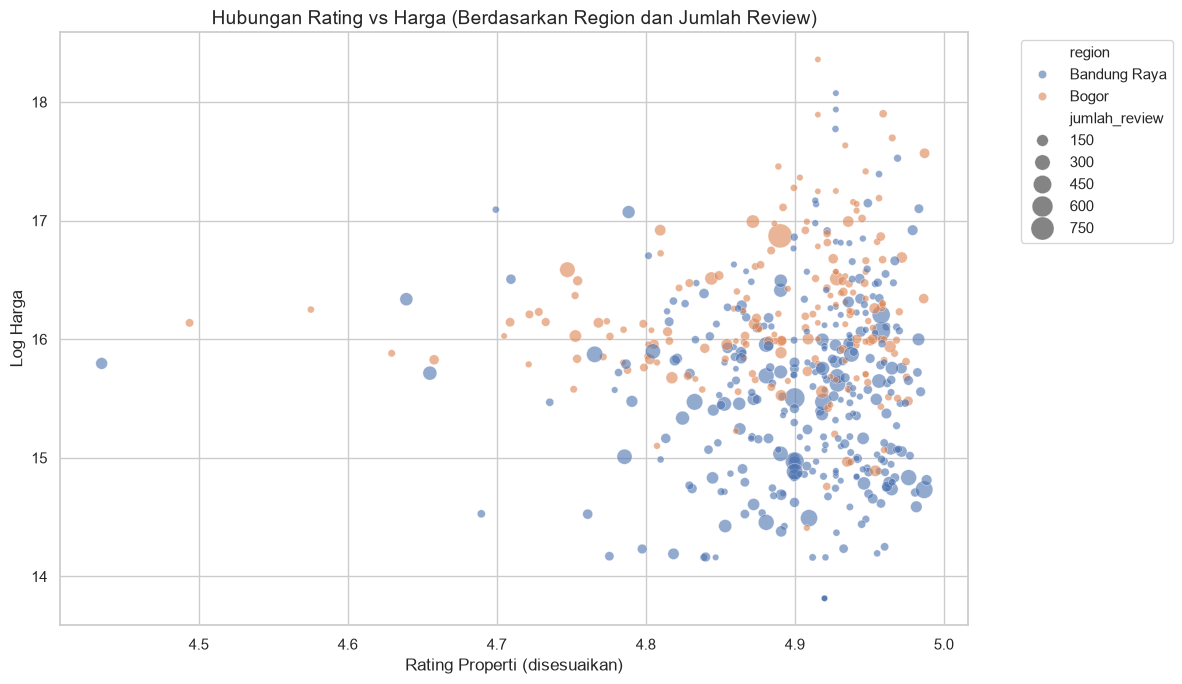

In [ ]:
# Filter data yang memiliki rating (drop NaN pada rating)
df_rating = df_eda.dropna(subset=['rating']).copy()

# Buat Scatterplot
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df_rating, 
    x='rating_adj', 
    y='log_harga', 
    hue='region', 
    size='jumlah_review',
    sizes=(20, 300),
    alpha=0.6
)

plt.title('Hubungan Rating vs Harga (Berdasarkan Region dan Jumlah Review)', fontsize=14)
plt.xlabel('Rating Properti (disesuaikan)', fontsize=12)
plt.ylabel('Log Harga', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [24]:
from scipy.stats import pearsonr, spearmanr

# 1. Siapkan data (hapus rating yang kosong)
data_korelasi = df_rating.dropna(subset=['rating_adj', 'log_harga'])

# 2. Uji Korelasi Pearson (Linear)
r_pearson, p_pearson = pearsonr(data_korelasi['rating_adj'], data_korelasi['log_harga'])

# 3. Uji Korelasi Spearman (Peringkat/Non-linear)
r_spearman, p_spearman = spearmanr(data_korelasi['rating_adj'], data_korelasi['log_harga'])

print("=== HASIL UJI KORELASI ===")
print(f"Jumlah data diuji: {len(data_korelasi)}")
print(f"\n1. Korelasi Pearson (r): {r_pearson:.3f} (p-value: {p_pearson:.4f})")
print(f"2. Korelasi Spearman (rho): {r_spearman:.3f} (p-value: {p_spearman:.4f})")

# Interpretasi otomatis
def interpretasi(r):
    if abs(r) < 0.2: return "Sangat lemah / Tidak ada korelasi"
    elif abs(r) < 0.4: return "Lemah"
    elif abs(r) < 0.6: return "Sedang"
    else: return "Kuat"

print(f"\nInterpretasi Pearson: {interpretasi(r_pearson)}")

=== HASIL UJI KORELASI ===
Jumlah data diuji: 495

1. Korelasi Pearson (r): -0.013 (p-value: 0.7658)
2. Korelasi Spearman (rho): -0.017 (p-value: 0.7124)

Interpretasi Pearson: Sangat lemah / Tidak ada korelasi


In [27]:
import statsmodels.formula.api as smf

# Siapkan data tanpa baris kosong
df_model = df_eda.dropna(subset=['rating_adj', 'log_harga', 'tipe_raw', 'region'])

# Buat Model Regresi untuk memprediksi log_harga berdasarkan rating_adj, region, dan tipe_raw
model = smf.ols(
    formula='log_harga ~ rating_adj + C(region) + C(tipe_raw)', 
    data=df_model
).fit()

# Hasil
print(model.summary().tables[1]) # Menampilkan tabel koefisien saja agar rapi

# 4. Ekstrak nilai R-squared
print(f"\nR-squared: {model.rsquared:.3f}")
print("Artinya: Variabel (Rating, Region, Tipe) menjelaskan", f"{(model.rsquared * 100):.1f}%", "dari variasi harga.")

                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept                        11.0703      1.817      6.093      0.000       7.500      14.641
C(region)[T.Bogor]                0.2446      0.059      4.147      0.000       0.129       0.361
C(tipe_raw)[T.Boutique hotel]    -0.5776      0.398     -1.452      0.147      -1.359       0.204
C(tipe_raw)[T.Bungalow]           0.4971      0.558      0.891      0.374      -0.600       1.594
C(tipe_raw)[T.Cabin]              0.5930      0.236      2.518      0.012       0.130       1.056
C(tipe_raw)[T.Condo]              0.0735      0.185      0.397      0.691      -0.290       0.437
C(tipe_raw)[T.Cottage]            0.9857      0.289      3.407      0.001       0.417       1.554
C(tipe_raw)[T.Earthen home]       0.9415      0.562      1.677      0.094      -0.162       2.045
C(tipe_raw)[T.Farm s

## Ringkasan Eksplorasi Data (EDA)

1. **Harga Berdasarkan Region**: Terdapat perbedaan harga yang sangat mencolok. Median harga di Puncak/Bogor (~10.2 Juta) hampir dua kali lipat median harga di Bandung Raya (~5.8 Juta). Ini mengonfirmasi bahwa Lokasi adalah faktor dominan dalam penentuan harga.
2. **Korelasi Rating vs Harga**: Uji korelasi sederhana (Pearson & Spearman) menunjukkan nilai yang sangat mendekati nol dan tidak signifikan (p-value > 0.05). Secara visual (scatterplot), sebaran data tidak membentuk pola linear.
3. **Regresi Linear Berganda (OLS)**:
   - Saat **Lokasi (Region)** dan **Tipe Properti (tipe_raw)** dikontrol, hubungan antara rating dan harga berubah drastis. 
   - `rating_adj` menjadi **positif dan signifikan** (coef = 0.8, p-value = 0.031). 
   - **Insight**: Ini adalah fenomena *Omitted Variable Bias*. Secara umum, rating tidak berkorelasi dengan harga. Namun, jika kita membandingkan properti dengan **tipe yang sama** di **lokasi yang sama**, properti dengan rating lebih tinggi terbukti memiliki harga yang lebih mahal (sekitar 8% lebih tinggi untuk setiap kenaikan 0.1 poin rating).
   - Model regresi ini mampu menjelaskan **50.9%** variasi harga properti.